<a href="https://colab.research.google.com/github/sameerc1234/Data_Visualization_lab/blob/main/Data_Visualization_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population

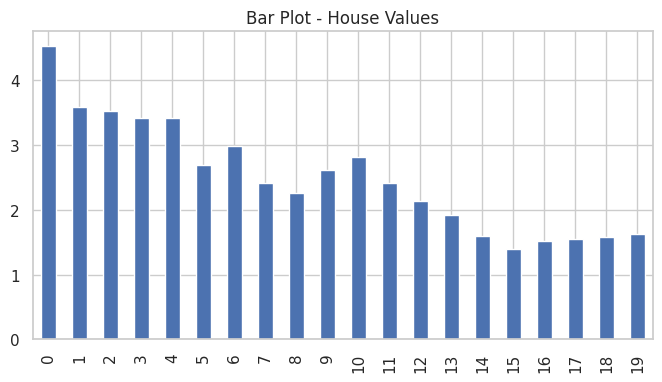

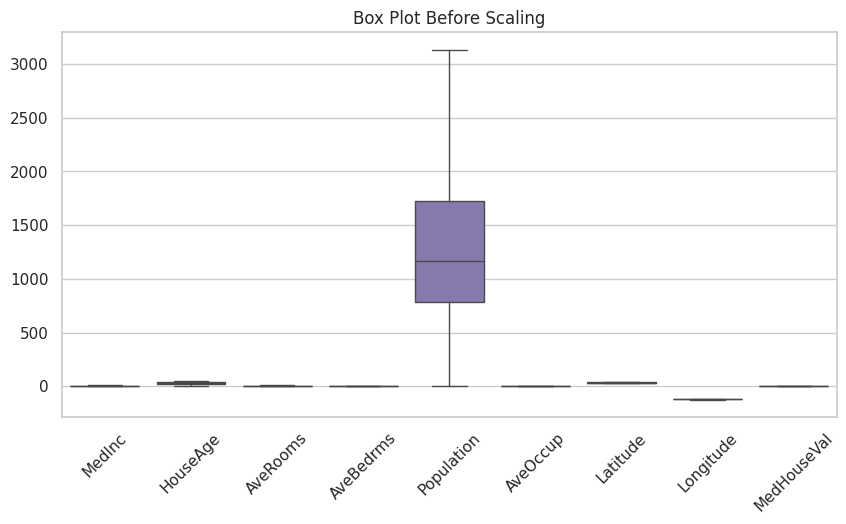

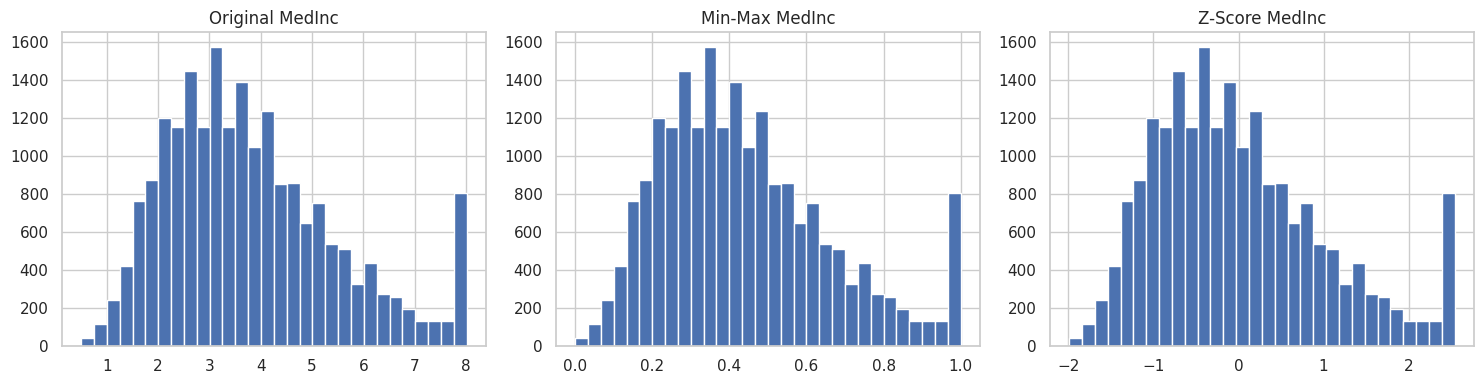

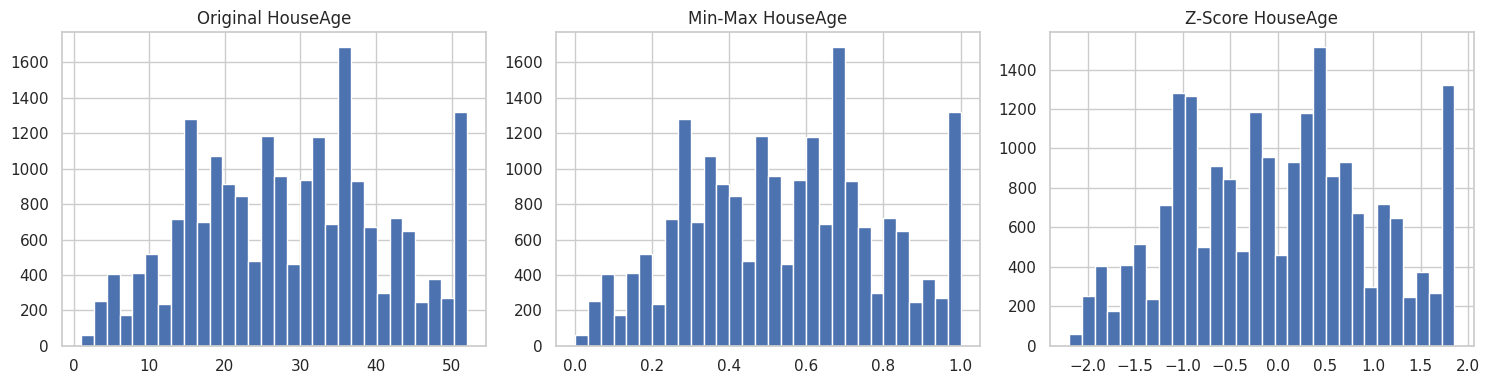

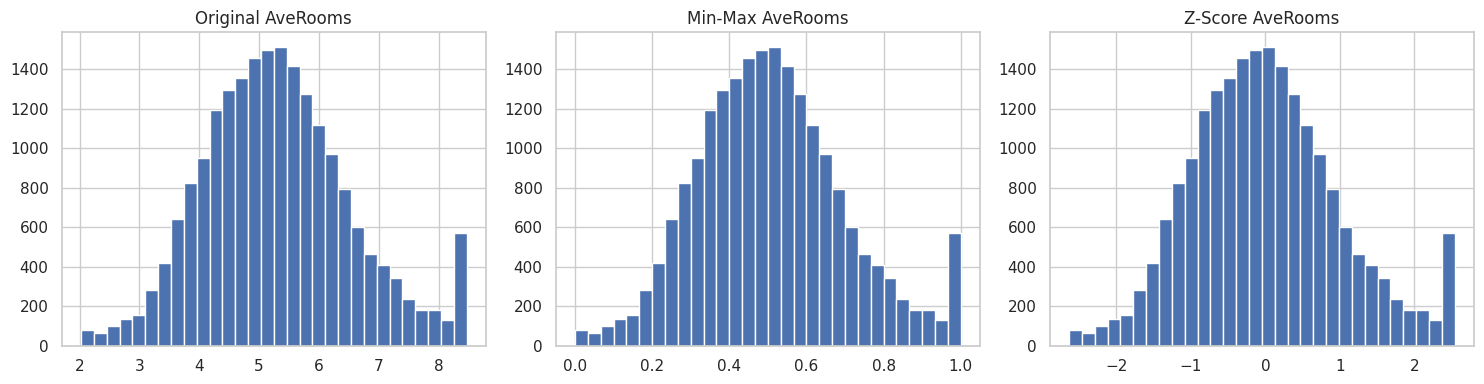

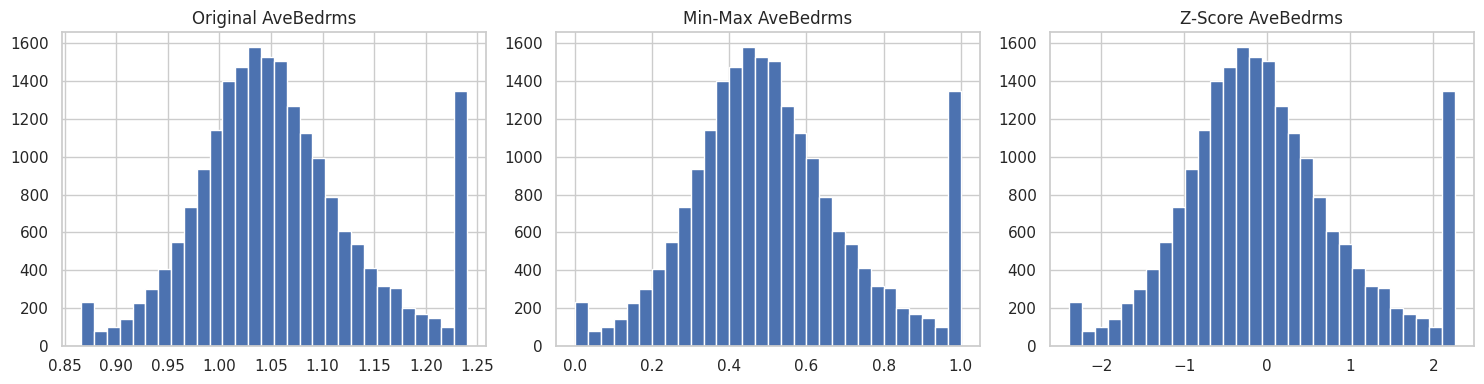

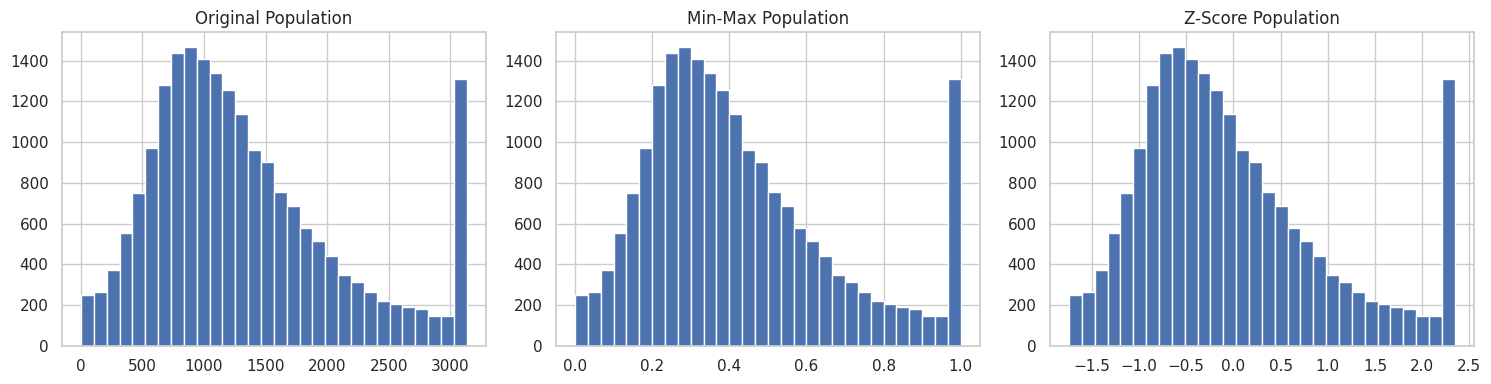

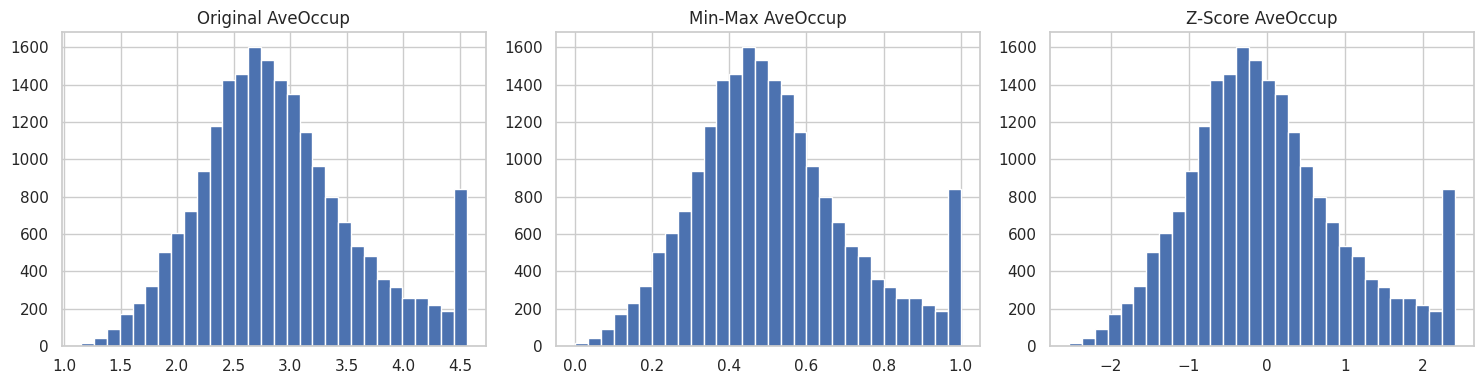

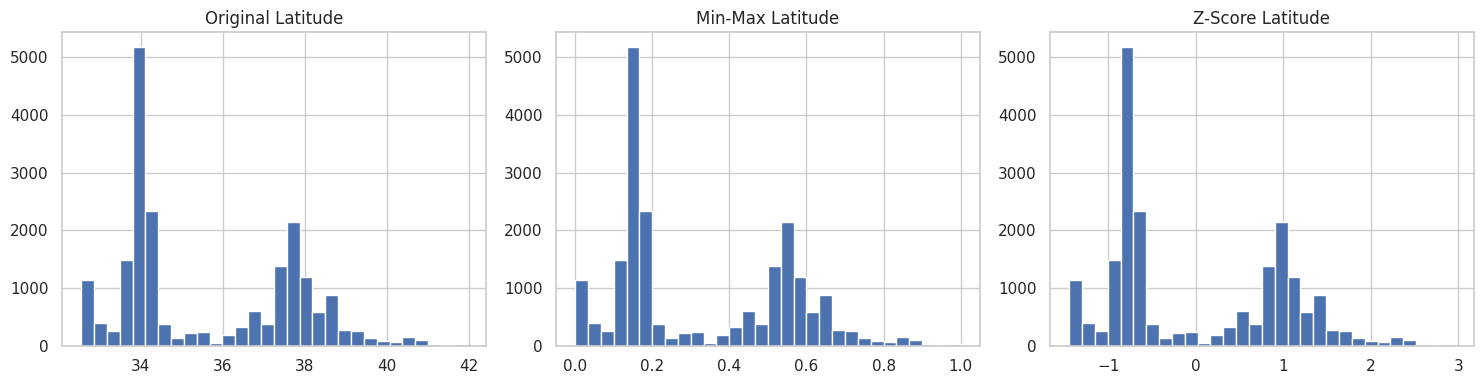

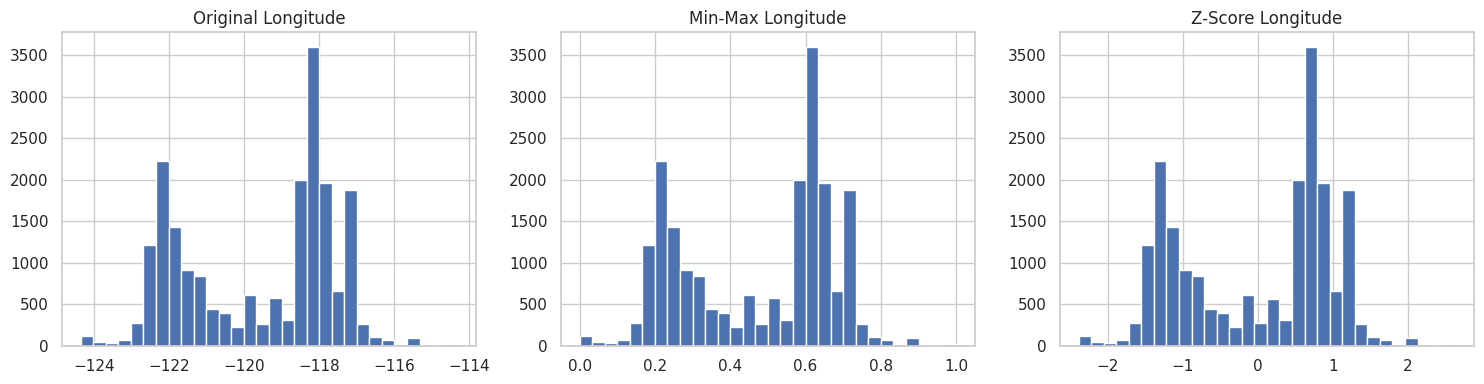

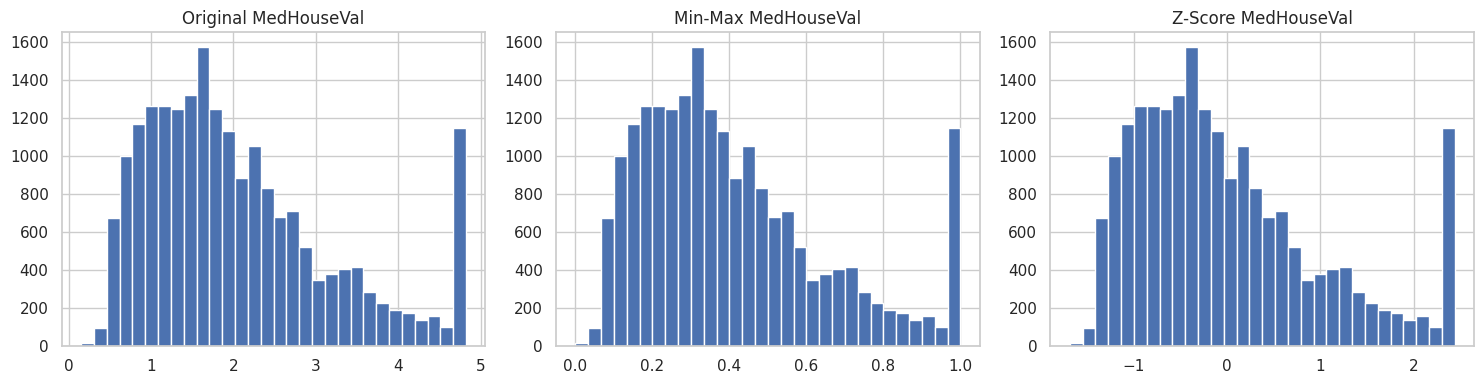

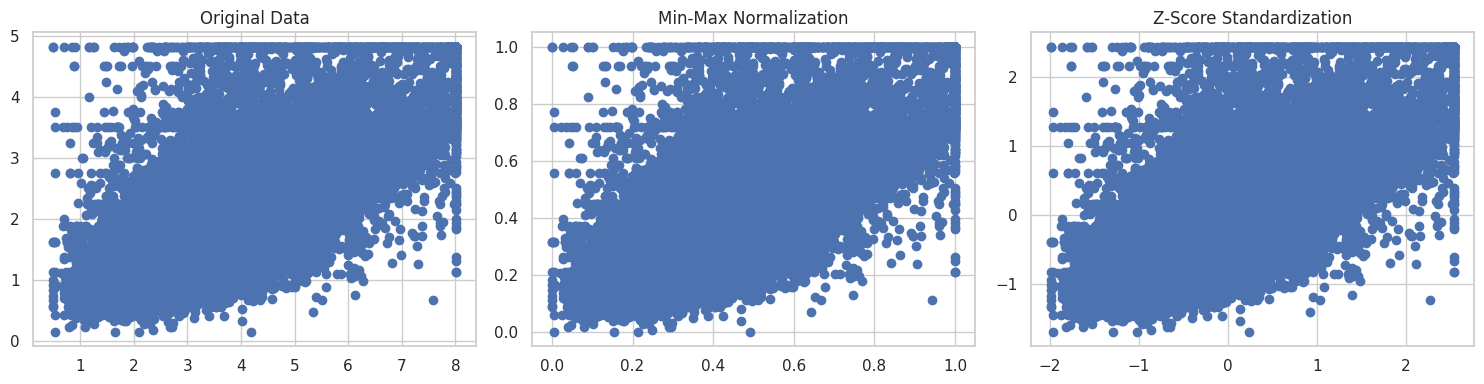

Preprocessing completed successfully!


In [ ]:

# California Housing Dataset - Simple Preprocessing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Load dataset
data = fetch_california_housing(as_frame=True)
df = data.frame

print(df.head())
print(df.info())

# 2. Handle missing values
df.fillna(df.median(numeric_only=True), inplace=True)

# 3. Remove duplicates
df.drop_duplicates(inplace=True)

# 4. Handle outliers using IQR
for col in df.select_dtypes(include=np.number).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    df[col] = df[col].clip(
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

# Save original data
original = df.copy()

# 5. Min-Max Normalization
minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    minmax.fit_transform(df),
    columns=df.columns
)

# 6. Z-score Standardization
standard = StandardScaler()
df_standard = pd.DataFrame(
    standard.fit_transform(df),
    columns=df.columns
)

print("\nMin-Max Data:")
print(df_minmax.head())

print("\nStandardized Data:")
print(df_standard.head())

# 7. Bar Plot
plt.figure(figsize=(8, 4))
df["MedHouseVal"].head(20).plot(kind="bar")
plt.title("Bar Plot - House Values")
plt.show()

# 8. Box Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=original.select_dtypes(include=np.number))
plt.title("Box Plot Before Scaling")
plt.xticks(rotation=45)
plt.show()

# 9. Histograms Before and After Scaling
for col in df.columns:
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.hist(original[col], bins=30)
    plt.title("Original " + col)

    plt.subplot(1, 3, 2)
    plt.hist(df_minmax[col], bins=30)
    plt.title("Min-Max " + col)

    plt.subplot(1, 3, 3)
    plt.hist(df_standard[col], bins=30)
    plt.title("Z-Score " + col)

    plt.tight_layout()
    plt.show()

# 10. Scatter Plot Before and After Scaling
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(original["MedInc"], original["MedHouseVal"])
plt.title("Original Data")

plt.subplot(1, 3, 2)
plt.scatter(df_minmax["MedInc"], df_minmax["MedHouseVal"])
plt.title("Min-Max Normalization")

plt.subplot(1, 3, 3)
plt.scatter(df_standard["MedInc"], df_standard["MedHouseVal"])
plt.title("Z-Score Standardization")

plt.tight_layout()
plt.show()

# 11. Save datasets
df.to_csv("cleaned_housing.csv", index=False)
df_minmax.to_csv("minmax_housing.csv", index=False)
df_standard.to_csv("standardized_housing.csv", index=False)

print("Preprocessing completed successfully!")
